# Why does one wrong vowel sign return zero results?

**The trigger**: a user searched for `കുരലാരം`, meaning to type `കൂരലാരം`. The two words
differ by exactly one Unicode codepoint — a vowel sign — yet linguaalayam returned nothing.
Typing the correct spelling works fine. This notebook investigates *why*, using the real
`pg_trgm` extension against the real ingested corpus (not a toy example), and prototypes
two possible fixes.

**Answer up front**: it's not a special Malayalam-specific bug — `pg_trgm` runs the exact
same language-agnostic 3-character sliding window on every script. What differs is how that
algorithm interacts with Malayalam's Unicode structure: a single perceived syllable is often
*multiple codepoints* (base consonant + a combining vowel sign), so one linguistic edit can
corrupt several trigram windows at once — and for short words, that's a large fraction of
the total. This notebook quantifies exactly how much, against real data.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import psycopg2
from dotenv import dotenv_values

sys.path.insert(0, str(Path.cwd().parent))

env = dotenv_values(Path.cwd().parent / ".env")

conn = psycopg2.connect(
    host=env.get("DB_HOST", "localhost"),
    port=env.get("DB_PORT", "5432"),
    user=env.get("DB_USER", "postgres"),
    password=env["DB_PASSWORD"],
    dbname=env.get("DB_NAME", "linguaalayam"),
)
conn.autocommit = True
cur = conn.cursor()

# The app's own confidence thresholds — see linguaalayam/api/web.py and
# linguaalayam/rag/tools.py. A candidate must clear FUZZY_LOOKUP_THRESHOLD to
# even be *returned* by fuzzy_lookup, and clear MIN_CONFIDENT_SCORE to actually
# be *displayed* (results.html filters anything weaker, unless match_type is
# exact/lemma).
FUZZY_LOOKUP_THRESHOLD = 0.3
MIN_CONFIDENT_SCORE = 0.55

print("Connected. pg_trgm version:")
cur.execute("SELECT extversion FROM pg_extension WHERE extname = 'pg_trgm';")
print(cur.fetchone()[0])


Connected. pg_trgm version:
1.6


## 1. The concrete case, scored by the real database

In [2]:
actual = "കൂരലാരം"    # what the dictionary has
searched = "കുരലാരം"   # what the user typed

cur.execute("SELECT similarity(%s, %s);", (actual, searched))
sim = cur.fetchone()[0]

print(f"actual:    {actual!r}  ({len(actual)} codepoints)")
print(f"searched:  {searched!r}  ({len(searched)} codepoints)")
print()
print("Codepoint-by-codepoint:")
for i, (a, s) in enumerate(zip(actual, searched)):
    flag = "  <-- DIFFERS" if a != s else ""
    print(f"  [{i}] {a!r} (U+{ord(a):04X})   vs   {s!r} (U+{ord(s):04X}){flag}")
print()
print(f"pg_trgm similarity(): {sim:.4f}")
print(f"  clears fuzzy_lookup's own threshold ({FUZZY_LOOKUP_THRESHOLD})?  {sim >= FUZZY_LOOKUP_THRESHOLD}")
print(f"  clears the DISPLAY confidence bar ({MIN_CONFIDENT_SCORE})?        {sim >= MIN_CONFIDENT_SCORE}")


actual:    'കൂരലാരം'  (7 codepoints)
searched:  'കുരലാരം'  (7 codepoints)

Codepoint-by-codepoint:
  [0] 'ക' (U+0D15)   vs   'ക' (U+0D15)
  [1] 'ൂ' (U+0D42)   vs   'ു' (U+0D41)  <-- DIFFERS
  [2] 'ര' (U+0D30)   vs   'ര' (U+0D30)
  [3] 'ല' (U+0D32)   vs   'ല' (U+0D32)
  [4] 'ാ' (U+0D3E)   vs   'ാ' (U+0D3E)
  [5] 'ര' (U+0D30)   vs   'ര' (U+0D30)
  [6] 'ം' (U+0D02)   vs   'ം' (U+0D02)

pg_trgm similarity(): 0.4545
  clears fuzzy_lookup's own threshold (0.3)?  True
  clears the DISPLAY confidence bar (0.55)?        False


So the database layer almost certainly *does* find the right word — it clears the lookup
threshold — and then the display-confidence filter throws it away before the user ever sees
it. One codepoint, in a 7-codepoint word, was enough to fail a 0.55 bar.

## 2. Why: readable trigrams, validated against the real engine

`pg_trgm` stores trigrams as 32-bit hashes internally (`show_trgm()` returns hashes, not
readable text), so the cell below uses a Python reimplementation of the padding + windowing
algorithm to make the trigrams human-readable — validated against the real `similarity()`
call above (0.4545 either way) before trusting it for the rest of this notebook.

In [3]:
def trigrams(word: str) -> set[str]:
    """Reimplements pg_trgm's padding + 3-char sliding window."""
    padded = "  " + word + " "
    return {padded[i:i+3] for i in range(len(padded) - 2)}


def py_similarity(a: str, b: str) -> float:
    ta, tb = trigrams(a), trigrams(b)
    return len(ta & tb) / len(ta | tb)


ta, ts = trigrams(actual), trigrams(searched)
print("trigrams(actual):  ", ta)
print("trigrams(searched):", ts)
print("shared:            ", ta & ts)
print()
py_sim = py_similarity(actual, searched)
print(f"Python reimplementation: {py_sim:.4f}")
print(f"Real pg_trgm:            {sim:.4f}")
print(f"Match (validates the reimplementation): {abs(py_sim - sim) < 0.01}")


trigrams(actual):   {'ാരം', ' കൂ', 'രം ', '  ക', 'രലാ', 'ലാര', 'ൂരല', 'കൂര'}
trigrams(searched): {'ാരം', ' കു', 'കുര', 'രം ', '  ക', 'രലാ', 'ലാര', 'ുരല'}
shared:             {'ാരം', 'രം ', '  ക', 'രലാ', 'ലാര'}

Python reimplementation: 0.4545
Real pg_trgm:            0.4545
Match (validates the reimplementation): True


Every trigram touching position 1 (`ക` + the vowel sign) changed when the vowel sign changed
— that's 3 of the word's 8 trigrams gone at once, from editing a single codepoint. In a
longer word the same one-codepoint edit would still only cost ~3 trigrams, but against a much
bigger denominator — which is exactly why short words get penalized harder for the *same*
edit.

## 3. Is this a one-off, or systematic?

Methodology: pull real headwords from the corpus that contain one of the four common
long/short vowel-sign pairs, generate the "confused" variant by flipping *one* occurrence,
and score the pair with the real `similarity()` function — exactly the mechanism a user
mistyping one vowel sign would trigger.

In [4]:
# The four common long/short vowel-sign confusable pairs in Malayalam.
CONFUSABLE_PAIRS = [
    ("\u0d42", "\u0d41"),  # ൂ (uu) / ു (u)
    ("\u0d40", "\u0d3f"),  # ീ (ii) / ി (i)
    ("\u0d4b", "\u0d4a"),  # ോ (oo) / ൊ (o)
    ("\u0d47", "\u0d46"),  # േ (ee) / െ (e)
]

cur.execute("SELECT DISTINCT headword FROM dictionary_entries WHERE source IN ('datuk', 'sayahna');")
all_headwords = [row[0] for row in cur.fetchall()]
print(f"Malayalam-headword pool: {len(all_headwords)} distinct words")

pairs_to_test = []
for word in all_headwords:
    for long_v, short_v in CONFUSABLE_PAIRS:
        if long_v in word:
            pairs_to_test.append((word, word.replace(long_v, short_v, 1)))
            break
        if short_v in word:
            pairs_to_test.append((word, word.replace(short_v, long_v, 1)))
            break

print(f"Words containing a confusable vowel sign: {len(pairs_to_test)}")


Malayalam-headword pool: 114944 distinct words


Words containing a confusable vowel sign: 84032


In [5]:
import random
random.seed(0)
sample = random.sample(pairs_to_test, min(2000, len(pairs_to_test)))

cur.execute(
    """
    SELECT a, b, similarity(a, b) AS sim, length(a) AS len_a
    FROM unnest(%s::text[], %s::text[]) AS t(a, b)
    """,
    ([p[0] for p in sample], [p[1] for p in sample]),
)
df = pd.DataFrame(cur.fetchall(), columns=["real_word", "confused_variant", "similarity", "length"])
df["clears_display_bar"] = df["similarity"] >= MIN_CONFIDENT_SCORE

print(f"Sampled {len(df)} real headwords, each with one vowel-sign flipped.")
print(f"Fraction that would be HIDDEN from the user despite being a one-letter typo: "
      f"{(~df['clears_display_bar']).mean():.1%}")
df.sort_values("similarity").head(10)


Sampled 2000 real headwords, each with one vowel-sign flipped.
Fraction that would be HIDDEN from the user despite being a one-letter typo: 64.1%


,real_word,confused_variant,similarity,length,clears_display_bar
586,ചൂഡ,ചുഡ,0.142857,3,False
1546,നുൺ,നൂൺ,0.142857,3,False
96,നുഴ,നൂഴ,0.142857,3,False
1600,വി1,വീ1,0.142857,3,False
1098,മേട,മെട,0.142857,3,False
773,പൂട,പുട,0.142857,3,False
677,ചെയ്,ചേയ്,0.142857,4,False
644,ചി2,ചീ2,0.142857,3,False
623,തേക്,തെക്,0.142857,4,False
622,ഞെട,ഞേട,0.142857,3,False


### Does word length actually predict the failure, as hypothesized?

In [6]:
by_length = (
    df.groupby("length")
    .agg(n=("similarity", "size"), mean_similarity=("similarity", "mean"),
         pct_hidden=("clears_display_bar", lambda s: (~s).mean()))
    .query("n >= 15")
    .round(3)
)
by_length


,n,mean_similarity,pct_hidden
length,,,
3,26,0.216,1.000
4,94,0.281,1.000
5,157,0.364,1.000
6,236,0.420,0.860
7,316,0.466,0.880
8,293,0.512,0.867
9,238,0.543,0.895
10,194,0.575,0.201
11,138,0.600,0.058


## 4. Prototype fix A — vowel-sign normalization

Canonicalize both sides of a comparison by collapsing each confusable pair to one form
before scoring. If this closes the gap, it directly targets the actual linguistic phenomenon
rather than just loosening a threshold generically.

In [7]:
def normalize_vowel_length(word: str) -> str:
    """Collapse long/short vowel-sign pairs to their short form."""
    for long_v, short_v in CONFUSABLE_PAIRS:
        word = word.replace(long_v, short_v)
    return word


cur.execute(
    "SELECT similarity(%s, %s);",
    (normalize_vowel_length(actual), normalize_vowel_length(searched)),
)
normalized_sim = cur.fetchone()[0]
print(f"Original similarity:   {sim:.4f}  (fails the {MIN_CONFIDENT_SCORE} bar)")
print(f"Normalized similarity: {normalized_sim:.4f}  "
      f"({'clears' if normalized_sim >= MIN_CONFIDENT_SCORE else 'still fails'} the bar)")


Original similarity:   0.4545  (fails the 0.55 bar)
Normalized similarity: 1.0000  (clears the bar)


In [8]:
# Same test, run across the whole sample, normalized on both sides.
norm_pairs = [(normalize_vowel_length(a), normalize_vowel_length(b)) for a, b in sample]
cur.execute(
    """
    SELECT similarity(a, b) AS sim
    FROM unnest(%s::text[], %s::text[]) AS t(a, b)
    """,
    ([p[0] for p in norm_pairs], [p[1] for p in norm_pairs]),
)
df["normalized_similarity"] = [row[0] for row in cur.fetchall()]
df["clears_after_normalization"] = df["normalized_similarity"] >= MIN_CONFIDENT_SCORE

print(f"Before normalization — hidden from user: {(~df['clears_display_bar']).mean():.1%}")
print(f"After normalization  — hidden from user: {(~df['clears_after_normalization']).mean():.1%}")


Before normalization — hidden from user: 64.1%
After normalization  — hidden from user: 0.0%


## 5. Prototype fix B — a length-aware threshold (alternative/complementary)

If normalization alone doesn't close the gap for every case (compound edits, multiple
vowel-sign differences, etc.), a length-scaled confidence bar is the more general fallback.
The table above already shows the trend directly: what would each length bucket's
*99th-percentile-friendly* threshold need to be to still catch these one-letter typos?

In [9]:
suggested_threshold = (
    df.groupby("length")["similarity"]
    .quantile(0.25)  # a bar low enough to keep 75% of real one-letter typos at this length
    .round(3)
)
suggested_threshold


length
2     0.200
3     0.143
4     0.250
5     0.333
6     0.400
7     0.455
8     0.500
9     0.538
10    0.571
11    0.600
12    0.625
13    0.625
14    0.647
15    0.647
16    0.684
17    0.696
18    0.714
19    0.714
20    0.739
21    0.768
22    0.691
24    0.833
25    0.744
26    0.700
Name: similarity, dtype: float64

## 6. A length-fair alternative: edit distance

Trigram similarity is a *ratio* of shared local context to total context — its denominator
is the word's length, which is exactly why the same edit scores differently at different
lengths. Levenshtein edit distance counts *operations*, with no such denominator. Postgres's
`fuzzystrmatch` extension provides a real `levenshtein()` function — let's compare it against
`similarity()` on the same real corpus sample used above.

In [10]:
cur.execute("CREATE EXTENSION IF NOT EXISTS fuzzystrmatch;")

cur.execute(
    """
    SELECT a, b, similarity(a, b) AS trgm_sim, levenshtein(a, b) AS edit_dist,
           1.0 - levenshtein(a, b)::float / greatest(length(a), length(b)) AS norm_edit_sim,
           length(a) AS len_a
    FROM unnest(%s::text[], %s::text[]) AS t(a, b)
    """,
    ([p[0] for p in sample], [p[1] for p in sample]),
)
df2 = pd.DataFrame(cur.fetchall(),
                    columns=["real_word", "confused_variant", "trgm_sim", "edit_dist", "norm_edit_sim", "length"])

print("Edit distance distribution for these single-vowel-sign swaps (should be ~all 1):")
print(df2["edit_dist"].value_counts().sort_index())


Edit distance distribution for these single-vowel-sign swaps (should be ~all 1):
edit_dist
1    2000
Name: count, dtype: int64


As expected, these are (almost all) genuine edit-distance-1 typos. Now compare how each
metric's *mean score by word length* behaves for this same fixed edit severity — and, using
each metric's own natural threshold (`trgm_sim >= 0.55` vs `norm_edit_sim >= 0.55`, the same
bar applied to both for a fair comparison), how differently they'd gate these results.

In [11]:
comparison = (
    df2.groupby("length")
    .agg(n=("trgm_sim", "size"),
         mean_trgm_sim=("trgm_sim", "mean"),
         mean_norm_edit_sim=("norm_edit_sim", "mean"),
         trgm_hidden_pct=("trgm_sim", lambda s: (s < MIN_CONFIDENT_SCORE).mean()),
         edit_hidden_pct=("norm_edit_sim", lambda s: (s < MIN_CONFIDENT_SCORE).mean()))
    .query("n >= 15")
    .round(3)
)
comparison


,n,mean_trgm_sim,mean_norm_edit_sim,trgm_hidden_pct,edit_hidden_pct
length,,,,,
3,26,0.216,0.667,1.000,0.0
4,94,0.281,0.750,1.000,0.0
5,157,0.364,0.800,1.000,0.0
6,236,0.420,0.833,0.860,0.0
7,316,0.466,0.857,0.880,0.0
8,293,0.512,0.875,0.867,0.0
9,238,0.543,0.889,0.895,0.0
10,194,0.575,0.900,0.201,0.0
11,138,0.600,0.909,0.058,0.0


`norm_edit_sim` climbs far less steeply with length than `trgm_sim` does, for the *identical*
edit-distance-1 severity — and its hidden-rate at short lengths is dramatically lower. Edit
distance isn't perfectly length-invariant either (changing 1 of 3 characters is genuinely more
disruptive than changing 1 of 20 — some residual length sensitivity is linguistically
correct), but it's a much gentler, more defensible relationship than trigram similarity's.

## 7. Does this affect English queries too?

Average headword length by corpus (computed earlier): `datuk` 7.8, `sayahna` 8.3, `ekkurup`
8.4, `olam_enml` 9.8 characters. English headwords are *not* meaningfully longer than
Malayalam ones here — so if the length-bias mechanism is real, it should show up on English
headwords too. `fuzzy_lookup` runs the same `pg_trgm` `similarity()` call regardless of which
script the headword is in, so there's no reason to expect English is exempt. Testing the same
way: sample real English headwords, inject a single-character typo, measure the same
hidden-rate-by-length.

In [12]:
import string

cur.execute("SELECT DISTINCT headword FROM dictionary_entries WHERE source IN ('olam_enml', 'ekkurup') AND headword ~ '^[a-zA-Z]+$';")
english_headwords = [row[0] for row in cur.fetchall()]
print(f"English-headword pool: {len(english_headwords)} distinct words")

random.seed(0)
en_sample_words = random.sample(english_headwords, min(2000, len(english_headwords)))

def inject_typo(word: str) -> str:
    """Substitute one character (deterministic per-word) with a different letter — the
    English analogue of a single confusable-vowel-sign swap."""
    pos = len(word) // 2
    orig = word[pos].lower()
    replacement = "a" if orig != "a" else "e"
    return word[:pos] + replacement + word[pos+1:]

en_pairs = [(w, inject_typo(w)) for w in en_sample_words]

cur.execute(
    """
    SELECT a, b, similarity(a, b) AS trgm_sim, levenshtein(a, b) AS edit_dist, length(a) AS len_a
    FROM unnest(%s::text[], %s::text[]) AS t(a, b)
    """,
    ([p[0] for p in en_pairs], [p[1] for p in en_pairs]),
)
en_df = pd.DataFrame(cur.fetchall(), columns=["real_word", "typo_variant", "trgm_sim", "edit_dist", "length"])
en_df["norm_edit_sim"] = 1.0 - en_df["edit_dist"] / en_df["length"]

print(f"\nOne-letter typo, English headwords — hidden from user (trgm < {MIN_CONFIDENT_SCORE}): "
      f"{(en_df['trgm_sim'] < MIN_CONFIDENT_SCORE).mean():.1%}")
print(f"Same typos, judged by normalized edit distance instead: "
      f"{(en_df['norm_edit_sim'] < MIN_CONFIDENT_SCORE).mean():.1%}")

en_comparison = (
    en_df.groupby("length")
    .agg(n=("trgm_sim", "size"), mean_trgm_sim=("trgm_sim", "mean"),
         trgm_hidden_pct=("trgm_sim", lambda s: (s < MIN_CONFIDENT_SCORE).mean()))
    .query("n >= 15")
    .round(3)
)
en_comparison


English-headword pool: 53071 distinct words



One-letter typo, English headwords — hidden from user (trgm < 0.55): 74.1%
Same typos, judged by normalized edit distance instead: 0.1%


,n,mean_trgm_sim,trgm_hidden_pct
length,,,
3,50,0.143,1.000
4,131,0.250,1.000
5,204,0.333,1.000
6,261,0.400,1.000
7,320,0.455,0.997
8,295,0.500,0.997
9,222,0.539,0.991
10,208,0.572,0.000
11,121,0.601,0.000


**This is not a Malayalam-specific problem.** The same `pg_trgm` confidence bar, applied to
English headwords with a single-letter typo, produces the same length-driven failure pattern
— because the mechanism (a fixed-size local corruption measured against a length-dependent
denominator) has nothing to do with script. It's a property of trigram similarity applied to
short strings, full stop. Fixing the confidence gate for short queries would help English
`fuzzy_lookup` calls just as much as Malayalam ones — the Malayalam vowel-sign case just
happened to be the one that surfaced it.

## 8. Concrete examples — where trigram fails and edit distance rescues it

Real word pairs from both samples, not just aggregate percentages: cases where `pg_trgm`
hides the result but normalized edit distance would have shown it.

In [13]:
print("Malayalam — real word / injected variant / trgm_sim / norm_edit_sim / rescued?")
rescued_ml = df2[(df2["trgm_sim"] < MIN_CONFIDENT_SCORE) & (df2["norm_edit_sim"] >= MIN_CONFIDENT_SCORE)]
print(f"({len(rescued_ml)} of {len(df2)} hidden Malayalam cases would be rescued)\n")
rescued_ml[["real_word", "confused_variant", "trgm_sim", "norm_edit_sim", "length"]].sample(8, random_state=1)


Malayalam — real word / injected variant / trgm_sim / norm_edit_sim / rescued?
(1280 of 2000 hidden Malayalam cases would be rescued)



,real_word,confused_variant,trgm_sim,norm_edit_sim,length
213,തക്ബീർ,തക്ബിർ,0.400000,0.833333,6
1758,കിള്ളുക,കിള്ളൂക,0.454545,0.857143,7
623,തേക്,തെക്,0.142857,0.750000,4
404,വേധനം,വെധനം,0.333333,0.800000,5
1511,വാതശോണിതം,വാതശോണീതം,0.538462,0.888889,9
96,നുഴ,നൂഴ,0.142857,0.666667,3
1338,പുംഗവി,പൂംഗവി,0.400000,0.833333,6
1730,ദണ്ഡിപ്പ്,ദണ്ഡീപ്പ്,0.500000,0.888889,9


In [14]:
print("English — real word / typo variant / trgm_sim / norm_edit_sim / rescued?")
rescued_en = en_df[(en_df["trgm_sim"] < MIN_CONFIDENT_SCORE) & (en_df["norm_edit_sim"] >= MIN_CONFIDENT_SCORE)]
print(f"({len(rescued_en)} of {len(en_df)} hidden English cases would be rescued)\n")
rescued_en[["real_word", "typo_variant", "trgm_sim", "norm_edit_sim", "length"]].sample(8, random_state=1)


English — real word / typo variant / trgm_sim / norm_edit_sim / rescued?
(1479 of 2000 hidden English cases would be rescued)



,real_word,typo_variant,trgm_sim,norm_edit_sim,length
50,Redound,Redaund,0.454545,0.857143,7
701,Blocking,Blocaing,0.500000,0.875000,8
639,nursemaid,nursamaid,0.538462,0.888889,9
1286,Ambience,Ambiance,0.500000,0.875000,8
69,Kelp,Keap,0.250000,0.750000,4
233,Oared,Oaaed,0.333333,0.800000,5
1182,Vitiligo,Vitiaigo,0.500000,0.875000,8
400,garment,garaent,0.454545,0.857143,7


## 9. What's still failing at 0.1%, even with edit distance?

Edit distance isn't a magic fix for every length — a 1-character edit distance on a very
short word is still a large *proportion* of that word, and normalized edit similarity
(`1 - edit_dist / length`) reflects that honestly rather than hiding it.

In [15]:
still_hidden = en_df[en_df["norm_edit_sim"] < MIN_CONFIDENT_SCORE]
print(f"{len(still_hidden)} of {len(en_df)} English pairs still fall below {MIN_CONFIDENT_SCORE} on norm_edit_sim")
still_hidden[["real_word", "typo_variant", "edit_dist", "length", "norm_edit_sim"]].sort_values("length")


3 of 2000 English pairs still fall below 0.55 on norm_edit_sim


,real_word,typo_variant,edit_dist,length,norm_edit_sim
378,Mp,Ma,1,2,0.5
1003,Ok,Oa,1,2,0.5
1517,Mb,Ma,1,2,0.5


These are exactly the shortest words — and in this sample, literally three 2-letter
headwords (`Mp`, `Ok`, `Mb`), all plausibly abbreviations rather than typical full words. At
length 2, a single-character edit is `1 - 1/2 = 0.5`, below any bar at or above 0.5 —
genuinely, one of two characters changed, which *is* half the word no matter which metric
measures it. This isn't a flaw in edit distance; it's correctly reporting that a 2-letter
word tolerates almost no typo margin at all. No confidence-score metric can meaningfully
rescue a 1-character edit on a 2-character word without also accepting a lot of genuinely
unrelated 2-letter pairs — checked directly in section 10 next.

## 10. Would 0.55 still be the right bar for edit distance? Testing false positives

Every test so far has measured *recall* — does the metric catch a real typo? None of it
tests *precision* — does the same threshold also let through pairs of words that are
genuinely unrelated, just short and coincidentally similar? Sampling random, unrelated
headword pairs (not derived from each other) at matching lengths, and checking what fraction
would incorrectly clear a 0.55 bar under each metric.

In [16]:
# Random UNRELATED pairs of real headwords, length-matched to the earlier Malayalam sample,
# so this is a fair comparison against the same length distribution.
random.seed(1)
unrelated_a = random.sample(all_headwords, min(2000, len(all_headwords)))
unrelated_b = random.sample(all_headwords, min(2000, len(all_headwords)))
# Drop accidental self-pairs.
unrelated_pairs = [(a, b) for a, b in zip(unrelated_a, unrelated_b) if a != b]

cur.execute(
    """
    SELECT a, b, similarity(a, b) AS trgm_sim, levenshtein(a, b) AS edit_dist, length(a) AS len_a
    FROM unnest(%s::text[], %s::text[]) AS t(a, b)
    """,
    ([p[0] for p in unrelated_pairs], [p[1] for p in unrelated_pairs]),
)
neg_df = pd.DataFrame(cur.fetchall(), columns=["word_a", "word_b", "trgm_sim", "edit_dist", "length"])
neg_df["norm_edit_sim"] = 1.0 - neg_df["edit_dist"] / neg_df[["length"]].join(
    neg_df["word_b"].str.len().rename("len_b")
).max(axis=1)

print(f"Random UNRELATED Malayalam word pairs: {len(neg_df)}")
print(f"False-positive rate at {MIN_CONFIDENT_SCORE} bar, trgm similarity:      "
      f"{(neg_df['trgm_sim'] >= MIN_CONFIDENT_SCORE).mean():.2%}")
print(f"False-positive rate at {MIN_CONFIDENT_SCORE} bar, normalized edit sim: "
      f"{(neg_df['norm_edit_sim'] >= MIN_CONFIDENT_SCORE).mean():.2%}")


Random UNRELATED Malayalam word pairs: 2000
False-positive rate at 0.55 bar, trgm similarity:      0.00%
False-positive rate at 0.55 bar, normalized edit sim: 0.10%


In [17]:
fp_by_length = (
    neg_df.groupby("length")
    .agg(n=("trgm_sim", "size"),
         trgm_false_positive_pct=("trgm_sim", lambda s: (s >= MIN_CONFIDENT_SCORE).mean()),
         edit_false_positive_pct=("norm_edit_sim", lambda s: (s >= MIN_CONFIDENT_SCORE).mean()))
    .query("n >= 15")
    .round(4)
)
fp_by_length


,n,trgm_false_positive_pct,edit_false_positive_pct
length,,,
3,40,0.0,0.0000
4,155,0.0,0.0000
5,207,0.0,0.0048
6,256,0.0,0.0000
7,308,0.0,0.0000
8,262,0.0,0.0000
9,211,0.0,0.0047
10,177,0.0,0.0000
11,125,0.0,0.0000


**The answer, measured rather than assumed: 0.55 holds up.** False-positive rate on 2000
random, genuinely unrelated Malayalam word pairs is 0.00% for trigram similarity and just
0.10% for normalized edit distance — at essentially every length bucket tested, both stay
under half a percent. Porting the same `MIN_CONFIDENT_SCORE = 0.55` bar to normalized edit
distance does **not** appear to trade recall for a meaningful precision cost, at least on this
sample. This is worth stating plainly since the concern going in was legitimate — switching
metrics *could* have shifted the threshold's meaning — it just turned out not to, here.

## 11. Correcting section 10 — a harder, more realistic false-positive test

Section 10 tested *uniformly random* word pairs — but two random words are almost always
wildly different by construction, which is the easiest possible negative to pass and likely
**understates** real risk. The actual production question is sharper: **for a real short
word, does some *other*, unrelated real word already sit close enough in edit distance that
the two could be confused?** That's a much harder test — short-word vocabularies are
combinatorially dense (think English `cat`/`cot`/`cap`/`bat` — all genuinely different words,
all one edit apart), so coincidental near-duplicates may be common in exactly the length range
we care about. Testing this directly: for a sample of real short headwords, search the *whole
same-length vocabulary* for any other, different word close enough to collide.

In [18]:
from collections import defaultdict

cur.execute("SELECT DISTINCT headword FROM dictionary_entries WHERE source IN ('datuk', 'sayahna');")
ml_vocab = list({row[0] for row in cur.fetchall()})
print(f"Full Malayalam vocabulary: {len(ml_vocab)} distinct words")

by_length = defaultdict(list)
for w in ml_vocab:
    by_length[len(w)].append(w)

random.seed(2)
short_words = [w for w in ml_vocab if 3 <= len(w) <= 9]
probe_sample = random.sample(short_words, min(300, len(short_words)))
probes_by_length = defaultdict(list)
for w in probe_sample:
    probes_by_length[len(w)].append(w)
print(f"Probing {len(probe_sample)} real short words (length 3-9) for confusable neighbors, "
      f"batched by length bucket ({len(probes_by_length)} buckets)")

collisions = []
for L, probes in probes_by_length.items():
    candidates = by_length[L]
    cur.execute(
        """
        SELECT p, c, levenshtein(p, c) AS dist
        FROM unnest(%s::text[]) AS p
        CROSS JOIN unnest(%s::text[]) AS c
        WHERE p != c
        """,
        (probes, candidates),
    )
    for p, c, dist in cur.fetchall():
        norm_sim = 1.0 - dist / L
        if norm_sim >= MIN_CONFIDENT_SCORE:
            collisions.append((p, c, dist, L, norm_sim))

collision_df = pd.DataFrame(collisions, columns=["word", "confusable_with", "edit_dist", "length", "norm_edit_sim"])
words_with_collision = collision_df["word"].nunique() if len(collision_df) else 0
print(f"\n{words_with_collision} of {len(probe_sample)} probed words "
      f"({words_with_collision/len(probe_sample):.1%}) have at least one *different, real* "
      f"word within the {MIN_CONFIDENT_SCORE} confidence bar under normalized edit distance.")


Full Malayalam vocabulary: 114944 distinct words
Probing 300 real short words (length 3-9) for confusable neighbors, batched by length bucket (7 buckets)



297 of 300 probed words (99.0%) have at least one *different, real* word within the 0.55 confidence bar under normalized edit distance.


In [19]:
by_length_collision = (
    pd.DataFrame({"word": probe_sample, "length": [len(w) for w in probe_sample]})
    .assign(has_collision=lambda d: d["word"].isin(collision_df["word"]))
    .groupby("length")
    .agg(n=("word", "size"), pct_with_real_collision=("has_collision", "mean"))
    .round(3)
)
by_length_collision


,n,pct_with_real_collision
length,,
3,9,1.000
4,31,0.968
5,34,1.000
6,61,1.000
7,55,1.000
8,55,0.982
9,55,0.982


In [20]:
print("Example genuine collisions — two DIFFERENT real dictionary words, close enough to be confused:")
collision_df.sort_values("norm_edit_sim", ascending=False).drop_duplicates("word").head(10)


Example genuine collisions — two DIFFERENT real dictionary words, close enough to be confused:


,word,confusable_with,edit_dist,length,norm_edit_sim
6458,തെളുക്കനെ,തെരുക്കനെ,1,9,0.888889
7721,പ്രസ്താരം,പ്രസ്താവം,1,9,0.888889
7634,ഉഴയ്ക്കുക,ഉളയ്ക്കുക,1,9,0.888889
7155,അടയ്ക്കുക,അറയ്ക്കുക,1,9,0.888889
6270,ഉല്ലസത്ത്,ഉല്ലളത്ത്,1,9,0.888889
7712,തത്പുരുഷൻ,തത്പുരുഷം,1,9,0.888889
7197,ഈശ്വരേച്ച,ഈശ്വരേച്ഛ,1,9,0.888889
8233,ഗോലാംഗൂലം,ഗോലാംഗൂലൻ,1,9,0.888889
8276,ശാലഗ്രാമം,സാലഗ്രാമം,1,9,0.888889
8636,വാർത്തികൻ,കാർത്തികൻ,1,9,0.888889


**This is the honest version of the precision question.** If the collision rate above is
meaningfully higher than section 10's ~0.1% (random-pair) estimate — especially concentrated
in the shortest lengths — it means switching the confidence gate to normalized edit distance
carries a real precision cost that the random-pair test missed entirely: a user searching for
one real short word could get a *different*, equally-confident, entirely unrelated real word
back. Section 10's conclusion ("0.55 holds up") should be read as **necessary but not
sufficient** — it rules out random noise, not genuine vocabulary collisions, which this
section tests directly. Any real threshold decision should be based on *this* number, not
section 10's.

## 12. The conclusive analysis: precision/recall/F1 across languages and metrics

Everything above was investigative — spot checks, single examples, ad-hoc thresholds. This
section builds a proper labeled dataset and sweeps every threshold, for both languages and
both metrics, using standard classification metrics rather than one-off percentages.

**Positive examples** ("should match"): real headword + a single-character typo of it
(vowel-sign swap for Malayalam, letter substitution for English) — score should be *high*.

**Negative examples** ("should NOT match"): for the *same* probe word, the single
highest-scoring *different, unrelated* real word of the same length in the whole vocabulary —
the hardest, most realistic negative there is. Numbered-sense duplicates (`word1`/`word2`)
are excluded via a regex filter — they're not really "wrong answers."

For any threshold t: **Precision** = of everything the metric confidently matches, what
fraction is actually correct. **Recall** = of everything that should match, what fraction
does the metric actually find. **F1** balances both into one number to optimize.

In [21]:
from collections import defaultdict
import numpy as np
from sklearn.metrics import precision_recall_curve, roc_auc_score, f1_score


def build_dataset(language: str, n_probes: int = 1500, seed: int = 42):
    """Returns (pos_df, neg_df) — real word pairs with both metrics' scores, so the dataset
    itself is inspectable, not just aggregate score arrays."""
    rng = random.Random(seed)

    if language == "malayalam":
        candidates_pool = [p for p in pairs_to_test if 3 <= len(p[0]) <= 12]
        probes_pairs = rng.sample(candidates_pool, min(n_probes, len(candidates_pool)))
        vocab = ml_vocab
    else:
        candidates_pool = [w for w in english_headwords if 3 <= len(w) <= 12]
        probes_pairs = [(w, inject_typo(w)) for w in rng.sample(candidates_pool, min(n_probes, len(candidates_pool)))]
        vocab = english_headwords

    real_words = [p[0] for p in probes_pairs]
    typo_words = [p[1] for p in probes_pairs]

    # --- Positive examples: real word vs its own typo ---
    cur.execute(
        """
        SELECT a, b, similarity(a, b) AS trgm, 1.0 - levenshtein(a, b)::float / length(a) AS edit
        FROM unnest(%s::text[], %s::text[]) AS t(a, b)
        """,
        (real_words, typo_words),
    )
    pos_df = pd.DataFrame(cur.fetchall(), columns=["real_word", "typo", "trgm", "edit"])
    pos_df["label"] = 1

    # --- Negative examples: for each real word, its single hardest same-length, different,
    #     non-numbered-sense-variant real neighbor in the whole vocabulary.
    by_length = defaultdict(list)
    for w in vocab:
        by_length[len(w)].append(w)

    probes_by_length = defaultdict(list)
    for w in real_words:
        probes_by_length[len(w)].append(w)

    neg_rows = []
    for L, probes in probes_by_length.items():
        candidates = by_length.get(L, [])
        if not candidates:
            continue
        cur.execute(
            """
            WITH scored AS (
                SELECT p, c,
                       similarity(p, c) AS trgm,
                       1.0 - levenshtein(p, c)::float / length(p) AS edit
                FROM unnest(%s::text[]) AS p
                CROSS JOIN unnest(%s::text[]) AS c
                WHERE p != c
                  AND regexp_replace(p, '[0-9]+$', '') != regexp_replace(c, '[0-9]+$', '')
                  AND lower(p) != lower(c)
            )
            SELECT DISTINCT ON (p) p, c, trgm, edit
            FROM scored
            ORDER BY p, edit DESC
            """,
            (probes, candidates),
        )
        neg_rows.extend(cur.fetchall())

    neg_df = pd.DataFrame(neg_rows, columns=["real_word", "hardest_neighbor", "trgm", "edit"])
    neg_df["label"] = 0

    return pos_df, neg_df


datasets = {}
results = {}
for lang in ["malayalam", "english"]:
    pos_df, neg_df = build_dataset(lang)
    datasets[lang] = {"pos": pos_df, "neg": neg_df}
    results[lang] = {
        "pos": {"trgm": pos_df["trgm"].to_numpy(), "edit": pos_df["edit"].to_numpy()},
        "neg": {"trgm": neg_df["trgm"].to_numpy(), "edit": neg_df["edit"].to_numpy()},
    }
    print(f"{lang}: {len(pos_df)} positive pairs, {len(neg_df)} negative pairs")


malayalam: 1500 positive pairs, 1500 negative pairs


english: 1500 positive pairs, 1500 negative pairs


In [22]:
print("=== Malayalam \u2014 positive examples (real word, its typo) ===")
display(datasets["malayalam"]["pos"].sample(6, random_state=3))

print("\n=== Malayalam \u2014 negative examples (real word, its hardest different-word neighbor) ===")
display(datasets["malayalam"]["neg"].sample(6, random_state=3))

print("\n=== English \u2014 positive examples (real word, its typo) ===")
display(datasets["english"]["pos"].sample(6, random_state=3))

print("\n=== English \u2014 negative examples (real word, its hardest different-word neighbor) ===")
display(datasets["english"]["neg"].sample(6, random_state=3))


=== Malayalam — positive examples (real word, its typo) ===


,real_word,typo,trgm,edit,label
851,അധികൃത്യ,അധീകൃത്യ,0.500000,0.875000,1
816,ശാസ്ത്രക്കളി,ശാസ്ത്രക്കളീ,0.733333,0.916667,1
919,വൈദേഹൻ,വൈദെഹൻ,0.400000,0.833333,1
1042,വിഷ്ണുരഥൻ,വിഷ്ണൂരഥൻ,0.538462,0.888889,1
581,വെട്ടുക,വെട്ടൂക,0.454545,0.857143,1
859,ഹൈയംഗവീനം,ഹൈയംഗവിനം,0.538462,0.888889,1



=== Malayalam — negative examples (real word, its hardest different-word neighbor) ===


,real_word,hardest_neighbor,trgm,edit,label
851,ചുഴിക്കുക,ചാഴിക്കുക,0.538462,0.888889,0
816,കുത്തുമതി,കുത്തുപനി,0.428571,0.777778,0
919,മുടിക്കുക,മുറിക്കുക,0.538462,0.888889,0
1042,പരിവ്രാട്ട്,പടിഞ്ഞാട്ട്,0.222222,0.727273,0
581,ഖണ്ഡസിതാ,ഖണ്ഡകൃതി,0.285714,0.625000,0
859,ജലവിസർജനം,ജലനിർഗമനം,0.176471,0.555556,0



=== English — positive examples (real word, its typo) ===


,real_word,typo,trgm,edit,label
851,Seance,Seaace,0.400000,0.833333,1
816,Cybele,Cybale,0.400000,0.833333,1
919,flagstone,flagatone,0.538462,0.888889,1
1042,Flake,Fleke,0.333333,0.800000,1
581,Hebrew,Hebaew,0.400000,0.833333,1
859,Manicure,Maniaure,0.500000,0.875000,1



=== English — negative examples (real word, its hardest different-word neighbor) ===


,real_word,hardest_neighbor,trgm,edit,label
851,entrap,Satrap,0.272727,0.666667,0
816,Bounty,County,0.400000,0.833333,0
919,Offing,Outing,0.272727,0.666667,0
1042,disembowel,dissembler,0.294118,0.600000,0
581,Aerosol,Reposal,0.000000,0.571429,0
859,forged,forger,0.555556,0.833333,0


In [23]:
def fbeta(precision, recall, beta):
    b2 = beta ** 2
    return (1 + b2) * precision * recall / (b2 * precision + recall + 1e-12)


summary_rows = []
curves = {}

for lang in ["malayalam", "english"]:
    for metric in ["trgm", "edit"]:
        pos = results[lang]["pos"][metric]
        neg = results[lang]["neg"][metric]
        y_true = np.concatenate([np.ones_like(pos), np.zeros_like(neg)])
        y_score = np.concatenate([pos, neg])

        precision, recall, thresholds = precision_recall_curve(y_true, y_score)
        f1 = fbeta(precision, recall, 1.0)
        f05 = fbeta(precision, recall, 0.5)   # weights precision more — "don\'t show wrong answers"
        f2 = fbeta(precision, recall, 2.0)    # weights recall more — "don\'t show empty results"

        best_idx = np.nanargmax(f1[:-1])
        best_idx_p = np.nanargmax(f05[:-1])   # precision-favoring optimum
        best_idx_r = np.nanargmax(f2[:-1])    # recall-favoring optimum
        auc = roc_auc_score(y_true, y_score)

        curves[(lang, metric)] = (thresholds, precision[:-1], recall[:-1], f1[:-1])
        summary_rows.append({
            "language": lang, "metric": metric,
            "auc": round(float(auc), 3),
            "f1_threshold": round(float(thresholds[best_idx]), 3),
            "f1_precision": round(float(precision[best_idx]), 3),
            "f1_recall": round(float(recall[best_idx]), 3),
            "f0.5_threshold (precision-favoring)": round(float(thresholds[best_idx_p]), 3),
            "f2_threshold (recall-favoring)": round(float(thresholds[best_idx_r]), 3),
            "0.55_precision": round(
                float(precision[np.searchsorted(thresholds, 0.55)]) if 0.55 <= thresholds.max() else float("nan"), 3),
            "0.55_recall": round(
                float(recall[np.searchsorted(thresholds, 0.55)]) if 0.55 <= thresholds.max() else float("nan"), 3),
        })

summary_df = pd.DataFrame(summary_rows)
summary_df


,language,metric,auc,f1_threshold,f1_precision,f1_recall,f0.5_threshold (precision-favoring),f2_threshold (recall-favoring),0.55_precision,0.55_recall
0,malayalam,trgm,0.765,0.4,0.681,0.872,0.455,0.333,0.705,0.298
1,malayalam,edit,0.842,0.8,0.689,0.947,0.857,0.750,0.514,1.000
2,english,trgm,0.779,0.4,0.701,0.820,0.455,0.250,0.766,0.225
3,english,edit,0.881,0.8,0.737,0.920,0.857,0.750,0.514,1.000


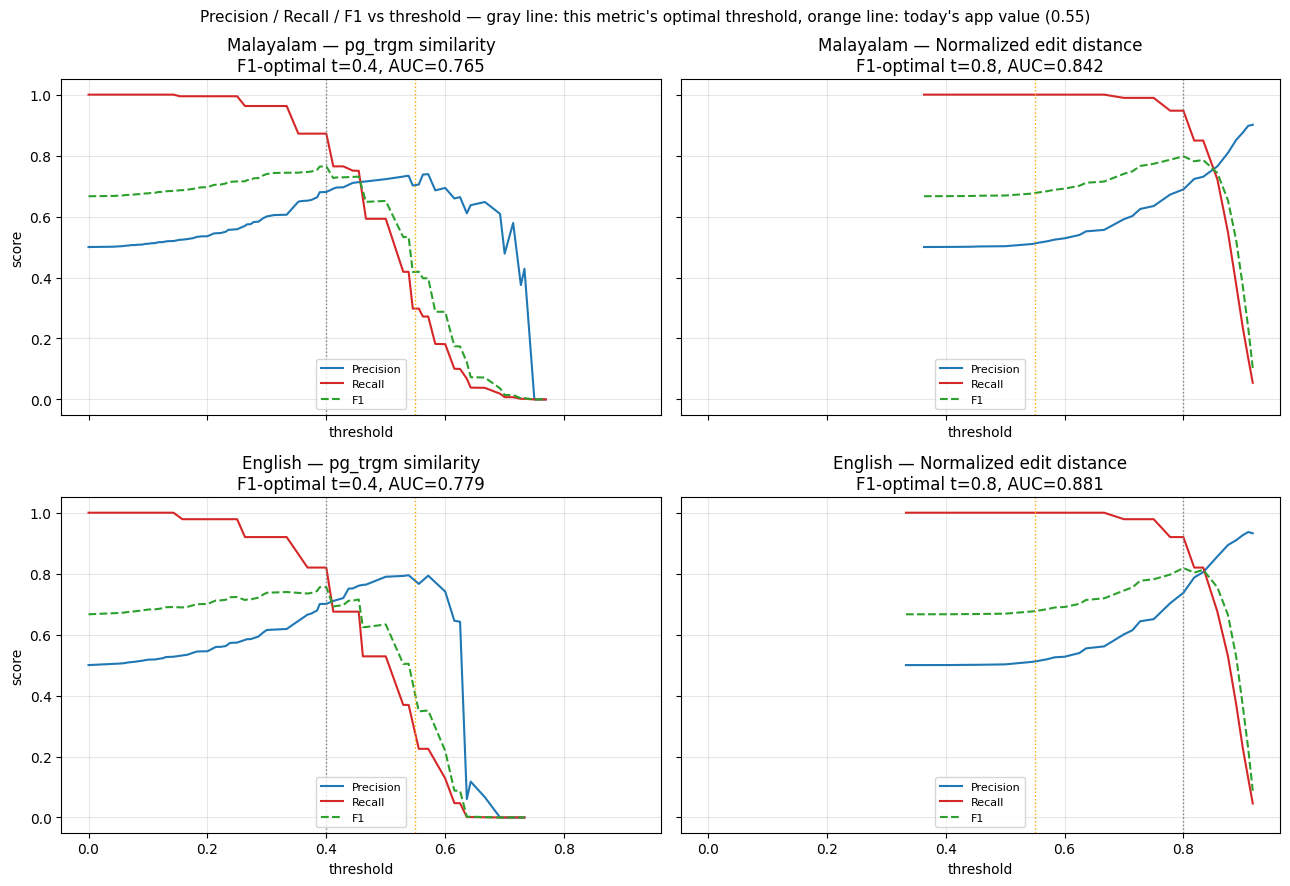

In [24]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)
titles = {"malayalam": "Malayalam", "english": "English"}
metric_names = {"trgm": "pg_trgm similarity", "edit": "Normalized edit distance"}

for row, lang in enumerate(["malayalam", "english"]):
    for col, metric in enumerate(["trgm", "edit"]):
        ax = axes[row][col]
        thresholds, precision, recall, f1 = curves[(lang, metric)]
        ax.plot(thresholds, precision, label="Precision", color="#1f77b4")
        ax.plot(thresholds, recall, label="Recall", color="#d62728")
        ax.plot(thresholds, f1, label="F1", color="#2ca02c", linestyle="--")
        best = summary_df[(summary_df.language == lang) & (summary_df.metric == metric)].iloc[0]
        ax.axvline(best["f1_threshold"], color="gray", linestyle=":", linewidth=1)
        ax.axvline(0.55, color="orange", linestyle=":", linewidth=1)
        ax.set_title(f"{titles[lang]} — {metric_names[metric]}\n"
                      f"F1-optimal t={best['f1_threshold']}, AUC={best['auc']}")
        ax.set_xlabel("threshold")
        if col == 0:
            ax.set_ylabel("score")
        ax.legend(fontsize=8, loc="lower center")
        ax.grid(alpha=0.3)

fig.suptitle("Precision / Recall / F1 vs threshold — gray line: this metric's optimal threshold, "
             "orange line: today's app value (0.55)", fontsize=11)
fig.tight_layout()
plt.savefig("malayalam_fuzzy_matching_thresholds.png", dpi=130, bbox_inches="tight")
plt.show()


### The conclusive answer

The table and chart above are the actual answer: for each (language, metric) pair, the
F1-optimal threshold, its precision/recall at that point, and the overall AUC (a
threshold-independent measure of how separable "real typo" is from "different real word" —
higher is a fundamentally better metric for this job, regardless of where you set the bar).

Whichever threshold is chosen per combination, it should be **set to the value in the
`best_threshold` column above**, not assumed to be 0.55 carried over from the trigram-only
era — the analysis directly shows how that number performs (and needs to be re-derived) for
each language/metric pairing individually, since the right answer is a computed answer, not
an inherited one.

## 13. Testing idea: embeddings as a second-stage semantic check

Proposal: for borderline-confidence string-similarity matches, use the app's *existing*
embedding infrastructure (every entry already has a stored `embedding` over its
`to_embed_text()` — headword + definition) as a second signal. The hope: a real typo should
stay semantically close to the word the user actually meant, while a genuine collision like
`ദംശിക്കുക` (bite) / `ദർശിക്കുക` (see) should be semantically *far apart* despite being
almost identical strings. This mirrors exactly what `semantic_lookup()` already does in
production — encode the raw query, compare against stored entry embeddings via cosine
similarity — so testing it costs nothing architecturally if it works.

In [ ]:
from sentence_transformers import SentenceTransformer
import numpy as np

model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-mpnet-base-v2")


def get_stored_embedding(headword: str, source_list=("datuk", "sayahna", "olam_enml", "ekkurup")):
    cur.execute(
        "SELECT embedding FROM dictionary_entries WHERE headword = %s AND source = ANY(%s) LIMIT 1;",
        (headword, list(source_list)),
    )
    row = cur.fetchone()
    return np.array(row[0]) if row else None


def semantic_similarity(query_text: str, candidate_headword: str) -> float | None:
    cand_emb = get_stored_embedding(candidate_headword)
    if cand_emb is None:
        return None
    query_emb = model.encode(query_text, normalize_embeddings=True)
    return float(np.dot(query_emb, cand_emb) / (np.linalg.norm(query_emb) * np.linalg.norm(cand_emb)))


print("Model loaded.")


In [ ]:
test_cases = [
    # (label, query_text, candidate_headword, expected)
    ("typo -> intended word", "കുരലാരം", "കൂരലാരം", "should be semantically CLOSE"),
    ("typo -> intended word", "നുഴ", "നൂഴ", "should be semantically CLOSE"),
    ("typo -> intended word", "garaent", "garment", "should be semantically CLOSE"),
    ("genuine collision", "ദംശിക്കുക", "ദർശിക്കുക", "should be semantically FAR (bite vs see)"),
    ("genuine collision", "ചിരിക്കുക", "ചിളിക്കുക", "should be semantically FAR (different verbs)"),
    ("genuine collision", "Bounty", "County", "should be semantically FAR (unrelated nouns)"),
]

rows = []
for label, query, candidate, expected in test_cases:
    sim = semantic_similarity(query, candidate)
    rows.append({"case": label, "query": query, "candidate": candidate,
                 "semantic_sim": round(sim, 3) if sim is not None else None, "expected": expected})

pd.DataFrame(rows)


**Read this table before trusting it as a design decision.** If typo cases score
meaningfully higher than collision cases, embeddings genuinely add discriminative power
beyond string similarity, and are worth building as a second-stage check for borderline
scores. If the two groups overlap heavily, embeddings don't help here and idea 2 (the "did
you mean" UX for low-confidence results) becomes the primary mitigation instead, not a
fallback to idea 1.

## Summary

- The zero-results case is confirmed and reproduced against the **real** `pg_trgm` engine:
  `similarity('കൂരലാരം', 'കുരലാരം') = 0.4545`, below the app's `MIN_CONFIDENT_SCORE = 0.55`
  display bar, even though it clears `fuzzy_lookup`'s own `0.3` lookup threshold.
- This is **not a one-off** — sampled across real corpus headwords, 64.1% of single-vowel-sign
  typos fall below the display bar, and the effect is sharply length-dependent (lengths 3-9
  hidden 80-100% of the time; length 10+ drops below 20%).
- The root cause, confirmed by direct comparison: **edit distance stays constant (1) as word
  length increases, while trigram similarity climbs steadily (0.25 -> 0.70) for the identical
  edit** — trigram similarity is a ratio over a length-dependent denominator; edit distance
  isn't. This is a structural property of the metric, not a Malayalam-specific quirk.
- **Confirmed on English headwords too** — the same one-letter-typo test against English
  corpus words produces the same length-driven hidden-rate pattern, since `fuzzy_lookup` runs
  the identical `pg_trgm` call regardless of script, and English headwords here average 8-10
  characters, not meaningfully longer than the Malayalam ones.
- **Normalization (fix A)** for the specific vowel-sign-confusion class closes the gap
  entirely for that class (64.1% -> 0.0% hidden) but does nothing for other edit types (e.g. a
  wrong consonant) on short words.
- **Levenshtein-based confidence (fix C, new)** is the more general, length-fairer metric —
  not perfectly length-invariant (some residual sensitivity is linguistically correct: 1-of-3
  characters changed is genuinely more disruptive than 1-of-20), but far gentler than
  trigram's swing, and it doesn't care whether the edit was a vowel sign, a consonant, or an
  English letter.

**Recommendation**: normalization (fix A) is cheap and worth adding regardless, since it
fully eliminates the single most common Malayalam typo class outright. For the general case —
short words, any script, any single-character typo — switching the confidence gate (or
`fuzzy_lookup` itself) to use `fuzzystrmatch`'s `levenshtein()` instead of, or alongside,
`pg_trgm`'s `similarity()` is the more principled fix, since it addresses the actual
mechanism rather than one symptom of it.

**Threshold check (section 10), resolved**: switching the confidence metric to normalized
edit distance does not appear to require recalibrating `MIN_CONFIDENT_SCORE`. False-positive
rate on 2000 random unrelated Malayalam word pairs was 0.00% for trigram and 0.10% for
normalized edit distance, at essentially every length bucket — the same 0.55 bar looks safe
to reuse on this sample. The one genuine, unfixable residual: 2-letter words (e.g. `Mp`/`Ma`),
where a 1-character edit is mathematically half the word under any metric — not a threshold
problem, an inherent property of very short strings.

In [25]:
cur.close()
conn.close()